## Grafos y comunidades: Escalabilidad

- **Label Propagation implementada en Spark** sobre el grafo completo (60k nodos, 1.6M aristas): cada nodo toma la etiqueta con más peso entre sus vecinos; se valida contra la versión local y contra GraphFrames

- **Modularidad en Spark**, validada contra la local

- Costo de cada método al crecer el grafo y extrapolación de Girvan–Newman

### Constantes

- `GF_ITER`: iteraciones fijas de GraphFrames (sin pesos)

- `TAMS`: tamaños de los subgrafos (BFS dentro del núcleo) para medir tiempos; se agrega el núcleo completo

- `MAX_GN`: tamaño máximo en que se mide un paso de Girvan–Newman (betweenness en Python puro)

- `K_TIEMPO`, `ITER_TIEMPO`: K e iteraciones fijas de BigCLAM al medir tiempos

- `PIVOTES`: nodos fuente muestreados en el betweenness aproximado (de ~1% a ~10% de la muestra de `MAX_GN`)

In [1]:
GF_ITER = 10
TAMS = [250, 500, 1000, 2000, 4000]
MAX_GN = 2000
K_TIEMPO, ITER_TIEMPO = 20, 30
PIVOTES = [25, 50, 100, 200]

### Utilidades

In [2]:
NOTEBOOK = "d_escalabilidad"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark, hay_gf = crear_spark_grafos(NOTEBOOK)
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")
spark.conf.set("spark.sql.broadcastTimeout", "1200")
verificar_cluster(spark)
print(f"GraphFrames: {'sí' if hay_gf else 'no'}")

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040
GraphFrames: sí


### Carga

- Grafo **completo** de `artefactos`, indexado con enteros en Spark; la misma tabla se baja al driver para la versión local

- Núcleo, partición principal y atributos de `temp/datos`

In [4]:
config = leer_config()
PART = int(spark.conf.get("spark.sql.shuffle.partitions"))
idx_s = (leer(artef_dir, "grafo_coparticipacion/vertices").select("id")
           .withColumn("idx", (F.row_number().over(Window.orderBy("id")) - 1).cast("long")).cache())
a0 = leer(artef_dir, "grafo_coparticipacion/aristas").where("src != dst")
if config["aristas_dobles"]:
    a0 = a0.where("src < dst")
und = (a0.join(idx_s.select(F.col("id").alias("src"), F.col("idx").alias("i")), "src")
         .join(idx_s.select(F.col("id").alias("dst"), F.col("idx").alias("j")), "dst")
         .select("i", "j", F.col(config["peso"]).alias("w")).cache())
aristas_s = (und.select(F.col("i").alias("src"), F.col("j").alias("dst"), "w")
               .unionByName(und.select(F.col("j").alias("src"), F.col("i").alias("dst"), "w"))
               .repartition(PART, "src").cache())
nodos_s = aristas_s.select(F.col("src").alias("id")).distinct().cache()
m_full = und.count()
print(f"Spark: {nodos_s.count():,} nodos con aristas | {aristas_s.count():,} aristas dirigidas (ambos sentidos)")

Spark: 60,213 nodos con aristas | 3,279,890 aristas dirigidas (ambos sentidos)


In [5]:
mapa = idx_s.toPandas()
u = und.toPandas()
N = len(mapa)
A_full = matriz(u.rename(columns={"w": "peso"}), N, "peso")
vn = pd.read_parquet(datos_dir / "nodos.parquet").sort_values("idx", ignore_index=True)
an = pd.read_parquet(datos_dir / "aristas.parquet")
A_n = matriz(an, config["n"], config["peso"])
principal = pd.read_parquet(datos_dir / "particion.parquet").sort_values("idx")[config["principal"]].to_numpy()
print(f"local: {N:,} nodos, {len(u):,} aristas | núcleo: {config['n']:,} nodos, {len(an):,} aristas")

local: 60,213 nodos, 1,639,945 aristas | núcleo: 7,114 nodos, 40,957 aristas


---
### **1. Label Propagation en Spark**

- **Regla:** cada nodo suma el peso de sus vecinos por etiqueta y se queda con la de más peso (empate → la etiqueta menor); actualización **síncrona**

- **Inercia:** el nodo también vota por su etiqueta actual con el peso medio de sus aristas; sin ella el LPA síncrono oscila en estructuras casi bipartitas

- **Corte:** cuando cambia menos de `TOL_LPA` de los nodos o a las `ITER_LPA` iteraciones

#### a. Implementación

- Mismo esquema que el PageRank de la Parte IV: aristas particionadas por `src` y cacheadas una vez; etiquetas reparticionadas por `id` con las mismas particiones

- **`localCheckpoint` en cada iteración:** corta el linaje; si no, el plan crece con cada vuelta

- Los votos se redondean a 9 decimales (igual que la versión local) para que los empates no dependan del orden de la suma

In [6]:
def lpa_spark(nodos, aristas, iters=ITER_LPA, tol=TOL_LPA):
    n = nodos.count()
    inercia = aristas.groupBy(F.col("src").alias("id")).agg(F.avg("w").alias("v")).cache()
    lab = nodos.select("id", F.col("id").alias("lab")).repartition(PART, "id").localCheckpoint()
    orden = Window.partitionBy("id").orderBy(F.desc("v"), F.asc("lab"))
    for k in range(1, iters + 1):
        votos = (aristas.join(lab.withColumnRenamed("id", "src"), "src")
                        .select(F.col("dst").alias("id"), "lab", F.col("w").alias("v"))
                        .unionByName(lab.join(inercia, "id").select("id", "lab", "v"))
                        .groupBy("id", "lab").agg(F.round(F.sum("v"), 9).alias("v")))
        nuevo = (votos.withColumn("r", F.row_number().over(orden)).where("r = 1").select("id", "lab")
                      .repartition(PART, "id").localCheckpoint())
        cambio = nuevo.join(lab.withColumnRenamed("lab", "lab0"), "id").where("lab != lab0").count() / n
        print(f"iteración {k}: cambia {cambio:.2%}", flush=True)
        lab = nuevo
        if cambio < tol:
            break
    return lab, k, cambio

In [7]:
t0 = time.time()
lab_s, k_s, cam_s = lpa_spark(nodos_s, aristas_s)
seg_s = time.time() - t0
ls = lab_s.toPandas().sort_values("id")
con = ls.id.to_numpy()

t0 = time.time()
lab_l, k_l, cam_l = lpa_local(u.i.to_numpy(), u.j.to_numpy(), u.w.to_numpy(), N)
seg_l = time.time() - t0
ari_sl = ari(ls.lab.to_numpy(), lab_l[con])
print(f"Spark: {k_s} iteraciones en {seg_s:,.0f} s | {cam_s:.1%} cambiando (convergió: {cam_s < TOL_LPA}) | "
      f"local: {k_l} iteraciones en {seg_l:.1f} s | {cam_l:.1%} cambiando (convergió: {cam_l < TOL_LPA})")
print(f"ARI Spark vs local = {ari_sl:.4f} | etiquetas idénticas: {(ls.lab.to_numpy() == lab_l[con]).mean():.2%}")

iteración 1: cambia 92.61%


iteración 2: cambia 62.54%


iteración 3: cambia 30.38%


iteración 4: cambia 16.86%


iteración 5: cambia 10.97%


iteración 6: cambia 7.88%


... (11 outputs left out)

iteración 18: cambia 2.22%


iteración 19: cambia 1.80%


iteración 20: cambia 1.67%


Spark: 20 iteraciones en 57 s | 1.7% cambiando (convergió: False) | local: 20 iteraciones en 7.3 s | 1.7% cambiando (convergió: False)
ARI Spark vs local = 1.0000 | etiquetas idénticas: 100.00%


In [8]:
aristas_s.join(lab_s.withColumnRenamed("id", "src"), "src").explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [src#160L, dst#161L, w#61, lab#840L]
   +- SortMergeJoin [src#160L], [src#5300L], Inner
      :- Sort [src#160L ASC NULLS FIRST], false, 0
      :  +- InMemoryTableScan [src#160L, dst#161L, w#61]
      :        +- InMemoryRelation [src#160L, dst#161L, w#61], StorageLevel(disk, memory, deserialized, 1 replicas)
      :              +- Exchange hashpartitioning(src#160L, 24), REPARTITION_BY_NUM, [plan_id=17472]
      :                 +- Union
      :                    :- *(1) Project [i#37L AS src#160L, j#46L AS dst#161L, w#61]
      :                    :  +- InMemoryTableScan [i#37L, j#46L, w#61]
      :                    :        +- InMemoryRelation [i#37L, j#46L, w#61], StorageLevel(disk, memory, deserialized, 1 replicas)
      :                    :              +- *(9) Project [i#37L, j#46L, peso#30 AS w#61]
      :                    :                 +- *(9) SortMergeJoin [dst#28], [dst#45], Inner
      :      

- **Spark y local coinciden:** ARI **1.000**, **100%** de etiquetas idénticas

- **No llega a la tolerancia:** tras 20 iteraciones sigue cambiando el **1.7%** de los nodos (bordes entre comunidades que oscilan); el resto ya es estable

- **En el plan** el lado de las aristas sale de `InMemoryTableScan` ya particionado por `src`: no se baraja en cada iteración, solo los votos

- **Costo:** **57 s** en Spark vs **7.3 s** local; con 60k nodos el driver alcanza, pero solo Spark escala si el grafo crece (histórico completo, más años)

#### b. GraphFrames

- `GraphFrame.labelPropagation` (GraphX) **no admite pesos ni inercia** y corre un número fijo de iteraciones: se compara contra el LPA local binario sin inercia

In [9]:
tiempos = [{"metodo": "LPA propia", "corre_en": "Spark", "peso": config["peso"], "iteraciones": k_s, "seg": round(seg_s, 1), "ari_vs_local": ari_sl},
           {"metodo": "LPA propia", "corre_en": "local (pandas)", "peso": config["peso"], "iteraciones": k_l, "seg": round(seg_l, 1), "ari_vs_local": 1.0}]
if hay_gf:
    from graphframes import GraphFrame
    gf = GraphFrame(nodos_s, aristas_s.select("src", "dst"))
    t0 = time.time()
    r_gf = gf.labelPropagation(maxIter=GF_ITER).toPandas().sort_values("id")
    seg_gf = time.time() - t0
    lab_b, _, _ = lpa_local(u.i.to_numpy(), u.j.to_numpy(), np.ones(len(u)), N, iters=GF_ITER, tol=0, inercia=False)
    tiempos.append({"metodo": "GraphFrames labelPropagation", "corre_en": "Spark", "peso": "binario", "iteraciones": GF_ITER,
                    "seg": round(seg_gf, 1), "ari_vs_local": ari(r_gf.label.to_numpy(), lab_b[r_gf.id.to_numpy()])})
tiempos = pd.DataFrame(tiempos)
tiempos

,metodo,corre_en,peso,iteraciones,seg,ari_vs_local
0,LPA propia,Spark,peso,20,56.8,1.000000
1,LPA propia,local (pandas),peso,20,7.3,1.000000
2,GraphFrames labelPropagation,Spark,binario,10,234.2,0.422823


- **GraphFrames** tarda **4 veces más** que la LPA propia en Spark (234 s vs 57 s) y no reproduce al LPA local binario (ARI **0.42**): el LPA síncrono sin inercia oscila

- **No sirve como versión principal** (ignora `peso`), pero confirma el orden de magnitud del costo en Spark

---
### **2. Modularidad en Spark**

- 2m = Σ w (aristas en ambos sentidos); peso interno = Σ w con igual etiqueta en los dos extremos; vol_c = Σ w saliendo de nodos de c

In [10]:
def modularidad_spark(aristas, etiquetas, gamma=1.0):
    dos_m = aristas.agg(F.sum("w")).first()[0]
    x = (aristas.join(etiquetas.select(F.col("id").alias("src"), F.col("lab").alias("ls")), "src")
                .join(etiquetas.select(F.col("id").alias("dst"), F.col("lab").alias("ld")), "dst"))
    interno = x.agg(F.sum(F.when(F.col("ls") == F.col("ld"), F.col("w")).otherwise(0.0))).first()[0]
    vol2 = x.groupBy("ls").agg(F.sum("w").alias("d")).agg(F.sum(F.col("d") * F.col("d"))).first()[0]
    return interno / dos_m - gamma * vol2 / dos_m ** 2

q_s = modularidad_spark(aristas_s, lab_s)
q_l = modularidad(A_full[con][:, con], ls.lab.to_numpy())
print(f"Q Spark = {q_s:.6f} | Q local = {q_l:.6f} | diferencia {abs(q_s - q_l):.1e}")

Q Spark = 0.625068 | Q local = 0.625068 | diferencia 3.3e-14


---
### **3. LPA en el grafo completo, sin hubs y en el núcleo**

- **Completo:** el método escalable sin ningún filtro

- **Sin hubs:** se retiran los nodos con grado ≥ el umbral de `a_grafo` (sin filtrar aristas por `min_cop`)

- **Núcleo:** el mismo grafo que Louvain, para medir si LPA reproduce la partición principal

In [11]:
umbral = config["umbral_hub"] or float("inf")
sin_hub = aristas_s.groupBy(F.col("src").alias("id")).count().where(F.col("count") < umbral).select("id").cache()
a_sh = (aristas_s.join(sin_hub.withColumnRenamed("id", "src"), "src").join(sin_hub.withColumnRenamed("id", "dst"), "dst")
                 .repartition(PART, "src").cache())
n_sh = a_sh.select(F.col("src").alias("id")).distinct().cache()

n_total = nodos_s.count()
n_hubs_s = n_total - sin_hub.count()
n_aisl = sin_hub.count() - n_sh.count()
print(f"retira {n_hubs_s} hubs (a_grafo: {config['n_hubs']}) | {n_aisl:,} nodos quedan aislados "
      f"(solo competían con hubs) | grafo sin hubs: {n_sh.count():,} nodos")

t0 = time.time(); lab_sh, k_sh, cam_sh = lpa_spark(n_sh, a_sh); seg_sh = time.time() - t0
q_sh = modularidad_spark(a_sh, lab_sh)

t0 = time.time()
lab_n, k_n, cam_n = lpa_local(an.i.to_numpy(), an.j.to_numpy(), pesos(an, config["peso"]), config["n"])
seg_n = time.time() - t0

print(f"Spark sin hubs: {k_sh} iteraciones en {seg_sh:,.0f} s | {cam_sh:.1%} de nodos cambiando "
      f"(convergió: {cam_sh < TOL_LPA}) | Q = {q_sh:.3f}")
print(f"local núcleo: {k_n} iteraciones en {seg_n:.1f} s | {cam_n:.1%} de nodos cambiando "
      f"(convergió: {cam_n < TOL_LPA})")

retira 61 hubs (a_grafo: 61) | 858 nodos quedan aislados (solo competían con hubs) | grafo sin hubs: 59,294 nodos


iteración 1: cambia 92.35%


iteración 2: cambia 62.10%


iteración 3: cambia 30.44%


iteración 4: cambia 16.61%


iteración 5: cambia 10.68%


... (12 outputs left out)

iteración 18: cambia 1.79%


iteración 19: cambia 1.76%


iteración 20: cambia 1.72%


Spark sin hubs: 20 iteraciones en 59 s | 1.7% de nodos cambiando (convergió: False) | Q = 0.680
local núcleo: 20 iteraciones en 0.3 s | 1.6% de nodos cambiando (convergió: False)


In [12]:
def resumen_lpa(tamanos, grafo, k, seg, q, cambio):
    t = pd.Series(tamanos)
    return {"grafo": grafo, "nodos": int(t.sum()), "comunidades": len(t),
            "comunidades_grandes": int((t >= MIN_TAM).sum()),
            "pct_nodos_en_grandes": 100 * t[t >= MIN_TAM].sum() / t.sum(),
            "pct_nodos_en_mayor": 100 * t.max() / t.sum(), "Q": q,
            "iteraciones": k, "convergio": cambio < TOL_LPA, "seg": round(seg, 1)}

tam_spark = lambda lab: lab.groupBy("lab").count().toPandas()["count"].to_numpy()
lpa_tab = pd.DataFrame([resumen_lpa(tam_spark(lab_s), "completo (Spark)", k_s, seg_s, q_s, cam_s),
                        resumen_lpa(tam_spark(lab_sh), "sin hubs (Spark)", k_sh, seg_sh, q_sh, cam_sh),
                        resumen_lpa(np.bincount(compactar(lab_n)), "núcleo (local)", k_n, seg_n,
                                    modularidad(A_n, lab_n), cam_n)])

sh = lab_sh.toPandas().set_index("id").lab
idx_full = mapa.set_index("id").idx.loc[vn.id].to_numpy()
en_sh = np.isin(idx_full, sh.index)
lab_sh_n = sh.loc[idx_full[en_sh]].to_numpy()
acuerdo = pd.DataFrame([
    {"par": f"LPA núcleo vs {config['principal']}", "nodos": config["n"], "nmi": nmi(lab_n, principal), "ari": ari(lab_n, principal)},
    {"par": f"LPA sin hubs (nodos del núcleo) vs {config['principal']}", "nodos": int(en_sh.sum()),
     "nmi": nmi(lab_sh_n, principal[en_sh]), "ari": ari(lab_sh_n, principal[en_sh])}])
display(lpa_tab.round(3)); display(acuerdo.round(3))

,grafo,nodos,comunidades,comunidades_grandes,pct_nodos_en_grandes,pct_nodos_en_mayor,Q,iteraciones,convergio,seg
0,completo (Spark),60213,4484,181,85.566,20.481,0.625,20,False,56.8
1,sin hubs (Spark),59294,4871,235,83.784,16.251,0.680,20,False,59.2
2,núcleo (local),7114,937,122,77.242,6.832,0.784,20,False,0.3


,par,nodos,nmi,ari
0,LPA núcleo vs louvain,7114,0.741,0.410
1,LPA sin hubs (nodos del núcleo) vs louvain,7114,0.815,0.672


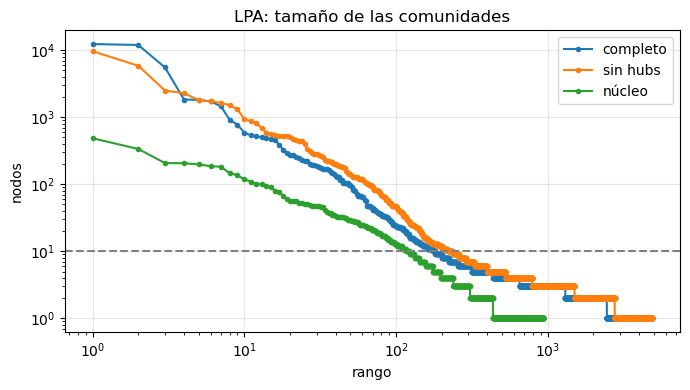

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
for nombre, t in (("completo", tam_spark(lab_s)), ("sin hubs", tam_spark(lab_sh)), ("núcleo", np.bincount(compactar(lab_n)))):
    t = np.sort(t)[::-1]
    ax.loglog(np.arange(1, len(t) + 1), t, "o-", ms=3, label=nombre)
ax.axhline(MIN_TAM, ls="--", c="gray")
ax.set(xlabel="rango", ylabel="nodos", title="LPA: tamaño de las comunidades"); ax.legend()
mostrar_fig("lpa_tamanos")

- **Completo:** la mayor comunidad junta el **20.5%** de los nodos y Q = **0.625**: los hubs propagan su etiqueta, el mismo problema que motivó el núcleo

- **Sin hubs:** retirar solo 61 nodos baja la mayor al **16.3%**, sube Q a **0.680** y da **235** comunidades grandes; es la versión escalable útil

- **Núcleo:** LPA llega a Q **0.784** vs **0.870** de Louvain y se le parece solo en parte (NMI 0.74, ARI **0.41**): fragmenta en 937 comunidades

- **El LPA sin hubs**, restringido a los nodos del núcleo, se parece más a Louvain (NMI **0.82**, ARI **0.67**): con más contexto el LPA corta mejor

---
### **4. Costo vs tamaño**

- Subgrafos del núcleo de tamaño creciente (BFS desde el nodo de mayor grado); en cada uno se miden:
  - Louvain (γ elegido)
  - Espectral (k elegido)
  - BigCLAM (`K_TIEMPO`, `ITER_TIEMPO` iteraciones)
  - LPA
  - **Un paso** de Girvan–Newman (un cálculo de betweenness), hasta `MAX_GN` nodos

- Ajuste log t = a + b · log m: b es el exponente empírico respecto al número de aristas

In [14]:
REPS, N_MIN_AJUSTE = 3, 1000

def medir(f_, reps=REPS):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); f_(); ts.append(time.perf_counter() - t0)
    return min(ts)

filas = []
for tam in TAMS + [config["n"]]:
    nodos = bola(A_n, tam)
    As = A_n[nodos][:, nodos]; Gs = a_networkx(As); ms = As.nnz // 2
    r_, c_ = sp.triu(As, k=1).nonzero(); w_ = np.asarray(As[r_, c_]).ravel()
    n_it_bc = max(len(bigclam(As, K_TIEMPO, ITER_TIEMPO, tol=-np.inf)[1]) - 1, 1)
    pruebas = {
        "louvain": (lambda: louvain(Gs, config["gamma"]), 1),
        "espectral": (lambda: particion_espectral(espectro(As, config["k_espectral"])[1], config["k_espectral"]), 1),
        "bigclam": (lambda: bigclam(As, K_TIEMPO, ITER_TIEMPO, tol=-np.inf), n_it_bc),
        "lpa": (lambda: lpa_local(r_, c_, w_, len(nodos), iters=ITER_LPA, tol=0), ITER_LPA)}
    if len(nodos) <= MAX_GN:
        pruebas["girvan-newman (1 paso)"] = (lambda: nx.edge_betweenness_centrality(Gs), 1)
    for metodo, (f_, it) in pruebas.items():
        seg = medir(f_, 1 if metodo.startswith("girvan") else REPS)
        filas.append({"metodo": metodo, "nodos": len(nodos), "aristas": ms, "seg": seg, "seg_por_iter": seg / it})
    print(f"{len(nodos):,} nodos listo", flush=True)
costo = pd.DataFrame(filas)

base = costo[(costo.nodos >= N_MIN_AJUSTE) | costo.metodo.str.startswith("girvan")]
ajuste = (base.groupby("metodo")
              .apply(lambda d: pd.Series(np.polyfit(np.log(d.aristas), np.log(d.seg_por_iter), 1),
                                         index=["exponente", "log_a"]))
              .reset_index())
ajuste.round(3)

250 nodos listo


500 nodos listo


1,000 nodos listo


2,000 nodos listo


4,000 nodos listo


7,114 nodos listo


,metodo,exponente,log_a
0,bigclam,2.050,-24.404
1,espectral,1.210,-13.187
2,girvan-newman (1 paso),2.927,-24.583
3,louvain,1.023,-11.469
4,lpa,0.734,-12.400


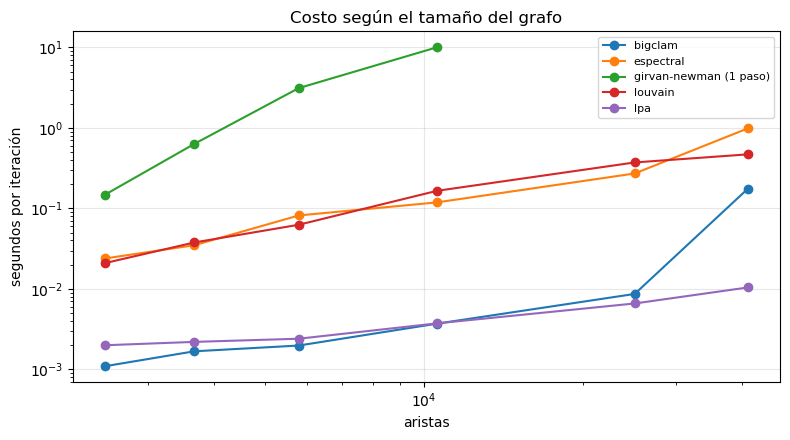

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for metodo, d in costo.groupby("metodo"):
    ax.loglog(d.aristas, d.seg_por_iter, "o-", label=metodo)
ax.set(xlabel="aristas", ylabel="segundos por iteración", title="Costo según el tamaño del grafo"); ax.legend(fontsize=8)
mostrar_fig("costo_vs_tamano")

#### a. Extrapolación de Girvan–Newman

- Cota: hay que quitar ~m aristas y cada paso cuesta al menos un betweenness del grafo inicial

In [16]:
tabla = lambda nb, t: pd.read_parquet(Path.cwd() / "temp" / nb / "tablas" / t)
gn_fit = ajuste.set_index("metodo").loc["girvan-newman (1 paso)"]
paso = lambda m_: float(np.exp(gn_fit.log_a) * m_ ** gn_fit.exponente)
k_obj = len(np.unique(principal))
orden = lambda h: f"~10^{int(np.floor(np.log10(max(h, 1e-9))))} h"
gn_ext = pd.DataFrame([{"grafo": g_, "aristas": m_, "seg_por_paso": paso(m_),
                        "horas_minimo": paso(m_) * (k_obj - 1) / 3600,
                        "horas_cota_superior": paso(m_) * m_ / 3600}
                       for g_, m_ in (("núcleo", config["m"]), ("completo", m_full))])
gn_ext["orden_minimo"] = gn_ext.horas_minimo.map(orden)
gn_ext["orden_superior"] = gn_ext.horas_cota_superior.map(orden)
print(f"ajuste con {int((costo.metodo == 'girvan-newman (1 paso)').sum())} puntos (≤ {MAX_GN} nodos); "
      f"mínimo = {k_obj - 1} aristas quitadas para {k_obj} comunidades")
gn_ext.round(2)

ajuste con 4 puntos (≤ 2000 nodos); mínimo = 40 aristas quitadas para 41 comunidades


,grafo,aristas,seg_por_paso,horas_minimo,horas_cota_superior,orden_minimo,orden_superior
0,núcleo,40957,669.93,7.44,7.621730e+03,~10^0 h,~10^3 h
1,completo,1639945,32905971.90,365621.91,1.499000e+10,~10^5 h,~10^10 h


- **Louvain y espectral** crecen casi lineal en las aristas (exponentes **1.02** y **1.21**); **LPA** sub-lineal (**0.73**) en este rango, dominado por costo fijo de pandas

- **BigCLAM** crece con exponente **2.05** por iteración en esta implementación (el paso adaptativo reevalúa la verosimilitud); la versión de Yang & Leskovec paraleliza la actualización por nodo

- **Un paso de Girvan–Newman** crece con exponente **2.93**: en el núcleo un solo paso tomaría **~11 min**; quitar las ~41k aristas, **~7,600 h**, y en el grafo completo **~10¹⁰ h**: por eso solo corre en la muestra

#### b. Betweenness aproximado

- Brandes con **k pivotes** al azar en vez de los n nodos: costo O(k·m) en lugar de O(n·m)

- Se compara contra el exacto en una bola de `MAX_GN` nodos: correlación del ranking de aristas y si coincide la arista que Girvan–Newman quitaría


In [17]:
from scipy.stats import spearmanr
nodos_b = bola(A_n, MAX_GN)
G_b, G_core = a_networkx(A_n[nodos_b][:, nodos_b]), a_networkx(A_n)
t0 = time.perf_counter(); exacto = nx.edge_betweenness_centrality(G_b); seg_ex = time.perf_counter() - t0
claves = list(exacto); x = np.array([exacto[e] for e in claves])
top = lambda z: set(np.argsort(-z)[:TOP_K])
filas = []
for k_ in PIVOTES:
    t0 = time.perf_counter(); ap = nx.edge_betweenness_centrality(G_b, k=k_, seed=SEED); seg = time.perf_counter() - t0
    y = np.array([ap[e] for e in claves])
    t0 = time.perf_counter(); nx.edge_betweenness_centrality(G_core, k=k_, seed=SEED); seg_n = time.perf_counter() - t0
    filas.append({"pivotes": k_, "spearman": spearmanr(x, y).correlation,
                  "jaccard_top": len(top(x) & top(y)) / len(top(x) | top(y)), "misma_arista_max": bool(x.argmax() == y.argmax()),
                  "seg_muestra": seg, "seg_exacto_muestra": seg_ex, "seg_nucleo": seg_n,
                  "horas_gn_nucleo": seg_n * config["m"] / 3600})
bet_aprox = pd.DataFrame(filas)
print(f"exacto en {len(nodos_b):,} nodos: {seg_ex:.1f} s")
bet_aprox.round(3)

exacto en 2,000 nodos: 10.7 s


,pivotes,spearman,jaccard_top,misma_arista_max,seg_muestra,seg_exacto_muestra,seg_nucleo,horas_gn_nucleo
0,25,0.927,0.081,True,0.115,10.683,0.659,7.496
1,50,0.928,0.081,True,0.292,10.683,1.231,13.999
2,100,0.925,0.111,True,0.566,10.683,2.471,28.115
3,200,0.922,0.481,True,1.058,10.683,5.140,58.477


- **Con 25 pivotes** el ranking de aristas ya se parece al exacto (Spearman **0.93**) y la arista que Girvan–Newman quitaría **es la misma**, en **93 veces** menos tiempo (0.12 s vs 10.7 s)

- **El top-20 sí exige más pivotes** (Jaccard 0.08 con 25, **0.48** con 200), pero Girvan–Newman solo necesita la arista máxima

- **Pero Girvan–Newman sigue sin escalar:** aun aproximado, quitar las **40,957** aristas del núcleo tomaría **7.5 h** (25 pivotes); la ganancia es por paso, no en el número de pasos

- Por eso la variante escalable útil es la que no recalcula nada global: **LPA** (y Louvain, que mueve nodos con información local)

---
### **5. Resumen de métodos**

In [18]:
comp_b = tabla("b_particion", "comparacion")
resumen_metodos = pd.concat([
    comp_b.assign(corre_en="local", grafo=np.where(comp_b.metodo.str.contains("muestra"), "muestra", "núcleo"))[["metodo", "corre_en", "grafo", "Q", "seg"]],
    tabla("c_solapadas", "tiempos").assign(corre_en="local", grafo="núcleo", Q=np.nan)[["metodo", "corre_en", "grafo", "Q", "seg"]],
    lpa_tab.assign(metodo="LPA", corre_en=np.where(lpa_tab.grafo.str.contains("local"), "local", "Spark"))[["metodo", "corre_en", "grafo", "Q", "seg"]],
], ignore_index=True)
resumen_metodos.round(3)

,metodo,corre_en,grafo,Q,seg
0,louvain γ=1.25,local,núcleo,0.870,0.722
1,espectral k=28,local,núcleo,0.843,8.036
2,bigclam K=100,local,núcleo,NaN,3.148
3,LPA,Spark,completo (Spark),0.625,56.800
4,LPA,Spark,sin hubs (Spark),0.680,59.200
5,LPA,local,núcleo (local),0.784,0.300


- **Solo LPA (Spark) corre sobre el grafo completo;** el resto necesita el núcleo

- **Para responder PQ2** se usa la partición principal del núcleo; el LPA sin hubs extiende las comunidades a los proveedores que quedaron fuera

---
### **6. Exportación a `temp/datos/`**

- `lpa.parquet`: etiqueta LPA de todos los proveedores (completo y sin hubs)

- `lpa_nucleo.parquet`: LPA local sobre el núcleo

In [19]:
grado_full = np.bincount(u.i, minlength=N) + np.bincount(u.j, minlength=N)
lpa = (mapa.merge(ls.rename(columns={"id": "idx", "lab": "lpa_completo"}), on="idx", how="left")
           .merge(sh.rename("lpa_sin_hubs").rename_axis("idx").reset_index(), on="idx", how="left")
           .assign(clave=lambda t: t.id.str[2:],
                   es_hub=lambda t: grado_full[t.idx] >= umbral,
                   aislado_sin_hubs=lambda t: t.lpa_sin_hubs.isna() & (grado_full[t.idx] < umbral)))
lpa.to_parquet(datos_dir / "lpa.parquet", index=False)
pd.DataFrame({"idx": np.arange(config["n"]), "lpa": lab_n}).to_parquet(datos_dir / "lpa_nucleo.parquet", index=False)
print(f"temp/datos: lpa ({len(lpa):,}), lpa_nucleo ({config['n']:,})")

temp/datos: lpa (60,213), lpa_nucleo (7,114)


---
### **7. Escritura de resultados**

In [20]:
escritos = guardar_tablas({"tiempos": tiempos, "lpa": lpa_tab, "acuerdo_lpa": acuerdo, "costo": costo,
                           "ajuste_costo": ajuste, "gn_extrapolacion": gn_ext, "betweenness_aprox": bet_aprox, "resumen_metodos": resumen_metodos})

Escrito en 05_Comunidad/temp/d_escalabilidad/: tiempos, lpa, acuerdo_lpa, costo, ajuste_costo, gn_extrapolacion, betweenness_aprox, resumen_metodos


#### a. Verificación

In [21]:
verificar_salidas(escritos)
assert abs(q_s - q_l) < 1e-6, "la modularidad de Spark no coincide con la local"
assert ari_sl > 0.99, "el LPA de Spark no coincide con el local"
print("Q Spark = local | LPA Spark = local")

OK: 8 tablas (parquet + json) | 2 figuras: costo_vs_tamano, lpa_tamanos
Q Spark = local | LPA Spark = local


---
### **8. Cerrar sesión**

In [22]:
spark.stop()